# 05 — Validation of the microglial state classifier

Notebook 04 transferred the Prinz atlas states (`Module_label`) to the Xenium microglia with Tangram and, as a check,
with a multinomial logistic regression. The classifier can be validated properly, and its probabilities do not depend
on the reference composition, so it can be the **primary** method. Tangram stays as a supplementary check.
This notebook validates it:

| Section | Question | How |
|---|---|---|
| 2 | Can the 8 states be told apart with the panel genes? | cross-validation **grouped by atlas sample** (`orig.ident`), so a sample's cells never inform its own prediction |
| 2 | Does it still work at Xenium depth (~600 transcripts / cell)? | the same CV with held-out atlas cells **thinned** (binomial down-sampling of counts) to the Xenium depth |
| 3 | Is the accuracy above chance? | **permutation null**: state labels shuffled, whole CV repeated |
| 4 | Are the probabilities calibrated? | reliability curves and Brier score per state |
| 5 | Do the predictions agree with genes the model never saw, on Xenium? | correlation of each state probability with a score of **held-out atlas markers** (ranks 101–200) |

The condition tests of notebook 04 need no permutation of the whole pipeline: the classifier never sees control /
mtDSB labels, so permuting the group labels at the end (as done there) is valid.

**Memory**: ~4–6 GB. Close other kernels holding large objects first.

In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, brier_score_loss, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

ATLAS = '../data/Mouse_Myeloid_atlas_v1.h5ad'
MG = '../data/microglia_tangram.h5ad'
RES = '../results/cellcharter/classifier_validation'
LABEL, GROUP = 'Module_label', 'orig.ident'
MAX_PER_STATE = 3000      # same subsample as notebooks 03 / 04
N_FOLDS, N_PERM = 5, 20
C, TOP, LFC = 0.1, 100, 0.5
SEED = 0

import os; os.makedirs(RES, exist_ok=True)
rng = np.random.default_rng(SEED)

## 1. Data

In [2]:
q = ad.read_h5ad(MG)                         # Xenium microglia, log-normalized X
atlas = ad.read_h5ad(ATLAS, backed='r')
aobs = atlas.obs[atlas.obs['Subclass_label'] == 'Microglia']
keep = (aobs.groupby(LABEL, observed=True, group_keys=False)
        .apply(lambda d: d.sample(min(len(d), MAX_PER_STATE), random_state=0)).index)
shared = [g for g in q.var_names if g in set(atlas.var_names)]
ref = atlas[keep, shared].to_memory()        # X = log-normalized (1e4), layers['counts'] = raw counts
ref.obs[LABEL] = ref.obs[LABEL].astype(str)
STATES = sorted(ref.obs[LABEL].unique())
y_all = ref.obs[LABEL].to_numpy()
groups = ref.obs[GROUP].astype(str).to_numpy()

xen_depth = q.obs['total_counts'].to_numpy()  # transcripts per Xenium microglia (target depth for thinning)
print(ref.shape, '| atlas samples:', len(np.unique(groups)), '| Xenium microglia median depth:', np.median(xen_depth))
print(ref.obs[LABEL].value_counts())

/tmp/ipykernel_185261/1448746477.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(min(len(d), MAX_PER_STATE), random_state=0)).index)


(19788, 5048) | atlas samples: 51 | Xenium microglia median depth: 602.0
Module_label
IFN                3000
Inflammation       3000
Proliferation      3000
Phagocytosis       3000
Surveillance       3000
MHC                2442
Neuroprotection    2133
Cytokine            213
Name: count, dtype: int64


In [3]:
def dense(X):
    return np.asarray(X.todense()) if sp.issparse(X) else np.asarray(X)


def markers(a, top=TOP, lfc=LFC):
    # union of the top atlas markers per state (Wilcoxon), as in notebooks 03 / 04
    a = a.copy()
    sc.tl.rank_genes_groups(a, LABEL, method='wilcoxon', n_genes=top)
    rg = sc.get.rank_genes_groups_df(a, group=None)
    return sorted(set(rg.loc[rg['logfoldchanges'] > lfc, 'names']))


def fit(Xtr, ytr):
    # z-score on the training data, L2 multinomial logistic regression with balanced class weights
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
    clf = LogisticRegression(max_iter=2000, class_weight='balanced', C=C).fit((Xtr - mu) / sd, ytr)
    return clf, mu, sd


def zself(X):
    # z-score a dataset on itself (how the Xenium cells are scaled)
    return (X - X.mean(0)) / (X.std(0) + 1e-6)


def thin(counts, depth_pool, rng):
    # binomial thinning of each cell to a depth drawn from the Xenium distribution, then log-normalize (1e4)
    counts = sp.csr_matrix(counts, dtype=np.float64)
    tot = np.asarray(counts.sum(1)).ravel()
    target = rng.choice(depth_pool, size=len(tot))
    p = np.minimum(1.0, target / np.maximum(tot, 1))
    out = counts.copy()
    out.data = rng.binomial(out.data.astype(np.int64), np.repeat(p, np.diff(out.indptr))).astype(np.float64)
    lib = np.asarray(out.sum(1)).ravel()
    out = sp.diags(1e4 / np.maximum(lib, 1)) @ out
    out.data = np.log1p(out.data)
    return out, np.asarray(out.getnnz(1) > 0)

## 2. Grouped cross-validation, at atlas depth and at Xenium depth
Folds are split by atlas sample (`StratifiedGroupKFold`), and marker genes are re-selected inside every training fold,
so neither the cells nor the gene choice of a test sample leak into training.
- **Atlas depth**: held-out cells scaled with the training mean / SD (same platform).
- **Xenium depth**: held-out cells thinned to the Xenium transcript counts, then scaled on themselves, as the Xenium
  microglia are in notebook 04. This is the closer proxy for real performance.

In [4]:
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(np.zeros(len(y_all)), y_all, groups))
P_full = np.zeros((len(y_all), len(STATES)))
P_thin = np.zeros((len(y_all), len(STATES)))
fold_genes = []
counts_all = ref.layers['counts']

for k, (tr, te) in enumerate(folds):
    genes = markers(ref[tr])
    fold_genes.append(genes)
    gi = [ref.var_names.get_loc(g) for g in genes]
    clf, mu, sd = fit(dense(ref.X[tr][:, gi]), y_all[tr])
    order = [list(clf.classes_).index(s) for s in STATES]
    P_full[te] = clf.predict_proba((dense(ref.X[te][:, gi]) - mu) / sd)[:, order]
    Xt, _ = thin(counts_all[te], xen_depth, rng)
    P_thin[te] = clf.predict_proba(zself(dense(Xt[:, gi])))[:, order]
    print(f'fold {k}: train {len(tr)} cells, test {len(te)} cells ({len(np.unique(groups[te]))} samples), genes {len(genes)}')


def summarise(P, name):
    pred = np.array(STATES)[P.argmax(1)]
    Y = (y_all[:, None] == np.array(STATES)[None, :]).astype(int)
    per_state = pd.DataFrame({
        'recall': [np.mean(pred[y_all == s] == s) for s in STATES],
        'precision': [np.mean(y_all[pred == s] == s) if (pred == s).any() else np.nan for s in STATES],
        'AUC (one-vs-rest)': [roc_auc_score(Y[:, i], P[:, i]) for i in range(len(STATES))],
        'Brier': [brier_score_loss(Y[:, i], P[:, i]) for i in range(len(STATES))],
        'n cells': [int((y_all == s).sum()) for s in STATES]}, index=STATES)
    overall = {'setting': name, 'balanced accuracy': balanced_accuracy_score(y_all, pred),
               'macro AUC': per_state['AUC (one-vs-rest)'].mean(), 'chance': 1 / len(STATES)}
    return per_state, overall, pred


ps_full, ov_full, pred_full = summarise(P_full, 'atlas depth')
ps_thin, ov_thin, pred_thin = summarise(P_thin, 'Xenium depth (thinned)')
overall = pd.DataFrame([ov_full, ov_thin]).set_index('setting')
per_state = pd.concat({'atlas depth': ps_full, 'Xenium depth': ps_thin}, axis=1)
overall.to_csv(f'{RES}/cv_overall.csv'); per_state.to_csv(f'{RES}/cv_per_state.csv')
display(overall.round(3)); display(per_state.round(3))

fold 0: train 15981 cells, test 3807 cells (9 samples), genes 552
fold 1: train 16293 cells, test 3495 cells (8 samples), genes 536
fold 2: train 14823 cells, test 4965 cells (13 samples), genes 549
fold 3: train 15828 cells, test 3960 cells (11 samples), genes 534
fold 4: train 16227 cells, test 3561 cells (10 samples), genes 540


,balanced accuracy,macro AUC,chance
setting,,,
atlas depth,0.677,0.928,0.125
Xenium depth (thinned),0.538,0.882,0.125


atlas depth                                             \
                     recall precision AUC (one-vs-rest)  Brier n cells   
Cytokine              0.662     0.406             0.975  0.010     213   
IFN                   0.745     0.641             0.939  0.074    3000   
Inflammation          0.472     0.518             0.875  0.107    3000   
MHC                   0.784     0.674             0.960  0.051    2442   
Neuroprotection       0.833     0.838             0.989  0.027    2133   
Phagocytosis          0.653     0.649             0.902  0.078    3000   
Proliferation         0.450     0.729             0.819  0.095    3000   
Surveillance          0.816     0.722             0.968  0.051    3000   

                Xenium depth                                             
                      recall precision AUC (one-vs-rest)  Brier n cells  
Cytokine               0.488     0.365             0.953  0.011     213  
IFN                    0.658     0.547             0.893  0.097    3000  
Inflammation           0.369     0.427             0.810  0.127    3000  
MHC                    0.568     0.563             0.902  0.077    2442  
Neuroprotection        0.463     0.712             0.943  0.066    2133  
Phagocytosis           0.620     0.455             0.840  0.119    3000  
Proliferation          0.449     0.528             0.763  0.117    3000  
Surveillance           0.688     0.733             0.953  0.062    3000

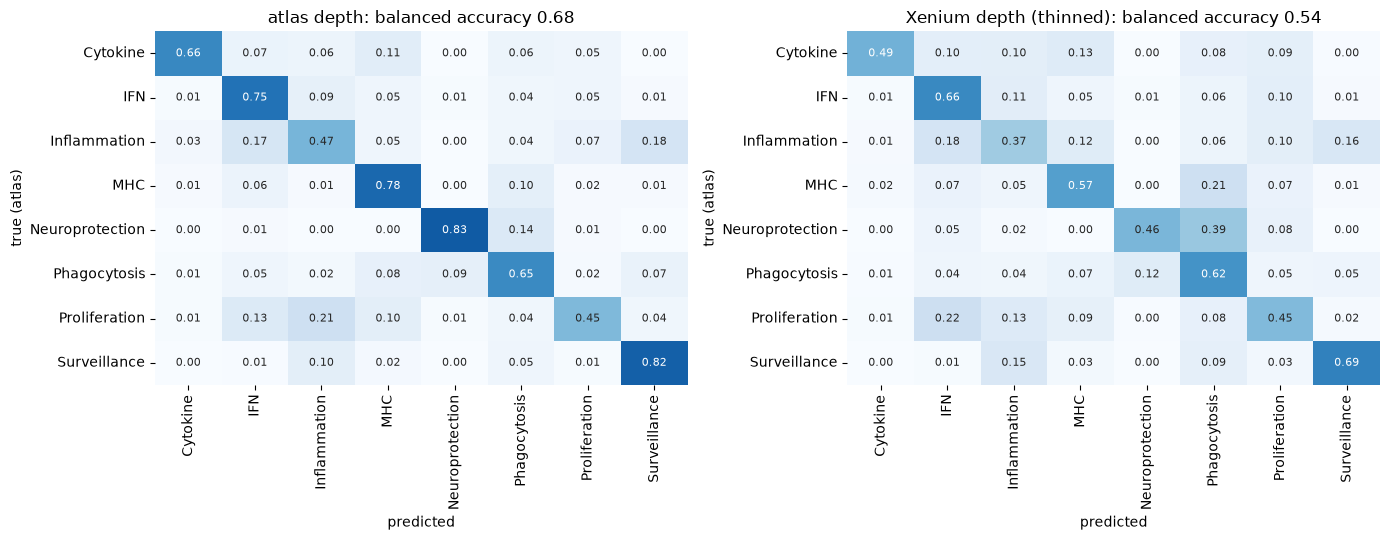

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (pred, name) in zip(axes, [(pred_full, 'atlas depth'), (pred_thin, 'Xenium depth (thinned)')]):
    cm = pd.DataFrame(confusion_matrix(y_all, pred, labels=STATES, normalize='true'), index=STATES, columns=STATES)
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax, cbar=False, annot_kws={'size': 8})
    ax.set_xlabel('predicted'); ax.set_ylabel('true (atlas)')
    ax.set_title(f"{name}: balanced accuracy {overall.loc[name, 'balanced accuracy']:.2f}")
fig.tight_layout()
fig.savefig(f'{RES}/confusion_matrices.png', dpi=150, bbox_inches='tight')

## 3. Permutation null
State labels are shuffled across cells and the whole cross-validation is repeated (fold marker genes kept fixed to save
time; re-selecting them on shuffled labels could only lower the null). With ~20,000 cells any real signal is far above
chance, so this is a sanity check; the per-state numbers of section 2 are the informative part.

In [6]:
def cv_balanced_accuracy(y):
    pred = np.empty(len(y), dtype=object)
    for (tr, te), genes in zip(folds, fold_genes):
        gi = [ref.var_names.get_loc(g) for g in genes]
        clf, mu, sd = fit(dense(ref.X[tr][:, gi]), y[tr])
        pred[te] = clf.predict((dense(ref.X[te][:, gi]) - mu) / sd)
    return balanced_accuracy_score(y, pred.astype(str))


null = np.array([cv_balanced_accuracy(rng.permutation(y_all)) for _ in range(N_PERM)])
obs = ov_full['balanced accuracy']
p_perm = (1 + np.sum(null >= obs)) / (1 + N_PERM)
print(f'observed balanced accuracy {obs:.3f} | null mean {null.mean():.3f}, max {null.max():.3f} | '
      f'p = {p_perm:.3f} ({N_PERM} permutations, smallest possible {1 / (1 + N_PERM):.3f})')
pd.Series(null, name='null balanced accuracy').to_csv(f'{RES}/permutation_null.csv', index=False)

observed balanced accuracy 0.677 | null mean 0.123, max 0.131 | p = 0.048 (20 permutations, smallest possible 0.048)


## 4. Calibration
For each state: among cells given probability ~x, what fraction really are that state? On the diagonal = calibrated.
Balanced class weights push probabilities of rare states up, so some departure from the diagonal is expected; what
matters for notebook 04 is that probabilities **rank** cells correctly (AUC) and are comparable between mice.

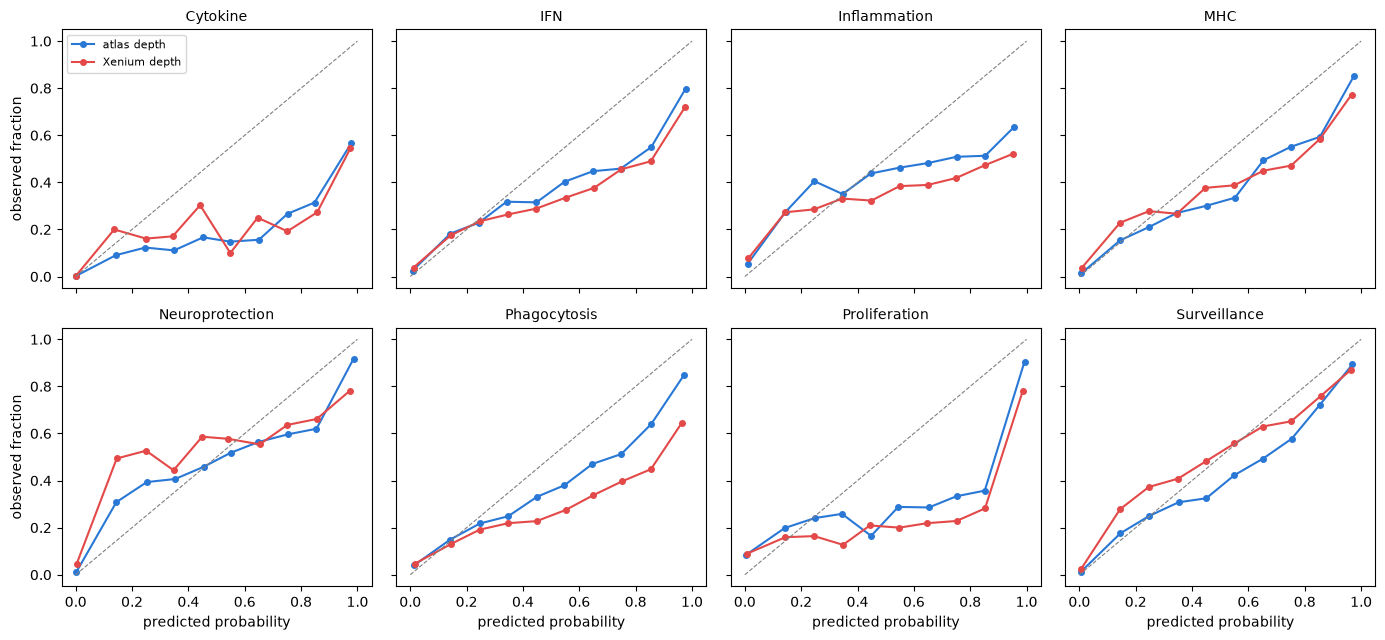

In [7]:
bins = np.linspace(0, 1, 11)
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharex=True, sharey=True)
for ax, (i, s) in zip(axes.ravel(), enumerate(STATES)):
    for P, name, colour in [(P_full, 'atlas depth', '#2a78d6'), (P_thin, 'Xenium depth', '#e34948')]:
        b = np.digitize(P[:, i], bins[1:-1])
        x = [P[b == j, i].mean() for j in range(10) if (b == j).sum() >= 20]
        y = [(y_all[b == j] == s).mean() for j in range(10) if (b == j).sum() >= 20]
        ax.plot(x, y, 'o-', color=colour, label=name, markersize=4)
    ax.plot([0, 1], [0, 1], color='grey', linewidth=0.8, linestyle='--')
    ax.set_title(s, fontsize=10)
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel('predicted probability')
for ax in axes[:, 0]:
    ax.set_ylabel('observed fraction')
fig.tight_layout()
fig.savefig(f'{RES}/calibration.png', dpi=150, bbox_inches='tight')

## 5. Check on the Xenium microglia with held-out genes
Final model: trained on the whole atlas subsample with its top-100 markers per state (as in notebook 04). For each state,
atlas markers ranked **101–200** that the model never used are scored in every Xenium microglia. If the classifier works
on Xenium, its probability for a state should correlate with that state's held-out score.

To make the test strict:
- **Score** = mean of the z-scored log expression of the held-out genes in each cell.
- **Partial Spearman correlation**, controlling for transcripts per cell: deeper cells detect more of everything, which
  alone could correlate any probability with any score.
- **Null**: 100 random gene sets of the same size, drawn from the same expression bins as the held-out genes and never
  from the training genes. A state **passes** when its correlation is above the 95th percentile of its null.
- **DAM-like** = Phagocytosis + Neuroprotection (sum of probabilities, union of held-out genes). The two states are
  confused at Xenium depth (section 2), so they are also tested as one.

In [9]:
a = ref.copy()
sc.tl.rank_genes_groups(a, LABEL, method='wilcoxon', n_genes=200)
rg = sc.get.rank_genes_groups_df(a, group=None)
rg = rg[rg['logfoldchanges'] > LFC]
rg['rank'] = rg.groupby('group', observed=True).cumcount()
train_genes = sorted(set(rg.loc[rg['rank'] < TOP, 'names']))

gi = [ref.var_names.get_loc(g) for g in train_genes]
clf, mu, sd = fit(dense(ref.X[:, gi]), y_all)
order = [list(clf.classes_).index(s) for s in STATES]
P_x = pd.DataFrame(clf.predict_proba(zself(dense(q[:, train_genes].X)))[:, order], index=q.obs_names, columns=STATES)
P_x.to_csv('../data/microglia_classifier_probs.csv')       # per-cell probabilities for downstream use (notebook 04)
P_x['DAM-like'] = P_x['Phagocytosis'] + P_x['Neuroprotection']

# z-scored log expression of all Xenium genes (cells x genes) and per-gene mean for expression-matched nulls
Zx = zself(dense(q.X)).astype(np.float32)
gene_mean = pd.Series(np.asarray(q.X.mean(0)).ravel(), index=q.var_names)
candidates = gene_mean.drop(train_genes, errors='ignore')
bins = pd.qcut(candidates.rank(method='first'), 20, labels=False)
col = {g: i for i, g in enumerate(q.var_names)}
depth_rank = pd.Series(q.obs['total_counts'].to_numpy()).rank().to_numpy()


def partial_spearman(x, y, z=depth_rank):
    # Spearman correlation of x and y after removing the linear effect of rank(z) from both ranks
    rx, ry = pd.Series(x).rank().to_numpy(), pd.Series(y).rank().to_numpy()
    A = np.column_stack([np.ones_like(z), z])
    res = lambda v: v - A @ np.linalg.lstsq(A, v, rcond=None)[0]
    return np.corrcoef(res(rx), res(ry))[0, 1]


held = {s: [g for g in rg.loc[(rg['group'] == s) & (rg['rank'] >= TOP), 'names'] if g in col and g not in set(train_genes)]
        for s in STATES}
held['DAM-like'] = sorted(set(held['Phagocytosis']) | set(held['Neuroprotection']))
N_NULL = 100
rows = []
for s, genes in held.items():
    if len(genes) < 5:
        rows.append({'state': s, 'held-out genes': len(genes), 'verdict': 'untested (< 5 held-out genes)'}); continue
    obs_rho = partial_spearman(P_x[s], Zx[:, [col[g] for g in genes]].mean(1))
    gbins = bins.reindex(genes).dropna().astype(int)
    null = []
    for _ in range(N_NULL):
        rand = [rng.choice(bins.index[bins == b]) for b in gbins]
        null.append(partial_spearman(P_x[s], Zx[:, [col[g] for g in rand]].mean(1)))
    null = np.array(null)
    rows.append({'state': s, 'held-out genes': len(genes), 'partial rho (held-out)': obs_rho,
                 'null mean': null.mean(), 'null 95th pct': np.quantile(null, 0.95),
                 'empirical p': (1 + np.sum(null >= obs_rho)) / (1 + N_NULL),
                 'verdict': 'passes' if obs_rho > np.quantile(null, 0.95) else 'fails'})
xen_check = pd.DataFrame(rows).set_index('state')
xen_check.to_csv(f'{RES}/xenium_heldout_marker_check.csv')
del Zx
xen_check.round(3)

,held-out genes,partial rho (held-out),null mean,null 95th pct,empirical p,verdict
state,,,,,,
Cytokine,50,0.074,-0.062,-0.016,0.010,passes
IFN,24,0.038,0.065,0.138,0.762,fails
Inflammation,0,NaN,NaN,NaN,NaN,untested (< 5 held-out genes)
MHC,24,0.181,-0.129,-0.011,0.010,passes
Neuroprotection,76,-0.021,0.116,0.182,1.000,fails
Phagocytosis,26,0.059,-0.005,0.013,0.010,passes
Proliferation,57,0.016,0.046,0.087,0.861,fails
Surveillance,26,0.155,-0.012,0.034,0.010,passes
DAM-like,96,0.053,-0.002,0.016,0.010,passes


- **Cross-validation**: balanced accuracy 0.68 at atlas depth and 0.54 at Xenium depth (chance 0.125); the permutation
  null is 0.117–0.131, so the classifier is far above chance.
- **Per state at Xenium depth**: Surveillance (AUC 0.95, well calibrated), MHC (0.90) and IFN (0.89) separate well;
  Phagocytosis and Neuroprotection are confused with each other (39% of Neuroprotection called Phagocytosis), so they
  are analysed together as **DAM-like**; Inflammation (0.81) and Proliferation (0.76) are unreliable; Cytokine has
  too few cells (213).
- **Calibration**: most states don't sit on the diagonal, they overestimate P, only Surveillance is near the diagonal. This
  does not affect per-mouse comparisons, which rely on ranking, but probabilities are not fractions of cells.
- **Xenium check**: only states that pass are interpreted in notebook 04. 